# 03c · Búsqueda de hiperparámetros del boosting (experimental)

**Propósito:** elegir los hiperparámetros de los tres modelos de boosting global (XGBoost, LightGBM y CatBoost) sobre las series con tratamiento por tienda del nb 03b, y guardar el pronóstico de la ventana de backtesting de la mejor configuración de cada uno.

**Contexto:** el nb 03b trata los quiebres por tienda, arma los datasets y hace la búsqueda SARIMAX. Este notebook toma sus datasets ya exportados (13.3) y corre la búsqueda del boosting en paralelo con la de SARIMAX. El nb 03d juntará los dos resultados con el seasonal naive y elegirá el modelo por artículo.

**Alcance:** independiente y solo de experimentación. Solo persiste la búsqueda (D1); el nb 04 no carga nada de aquí. Se lee lo exportado por el 03b, que no se modifica.

**Etapas** (el estado de cada una vive en `specs/001-abc-xyz-share-forecast/nb03c-etapas.md`):

| # | Etapa |
|---|---|
| 0 | Decisiones y reglas |
| 1 | Carga de las entradas del nb 03b |
| 2 | Métrica de la búsqueda: WRMSSE (pesos y referencia del seasonal naive) |
| 3 | XGBoost: piloto, búsqueda y backtesting (nb 04, Etapa 13a) |
| 4 | LightGBM: piloto, búsqueda y backtesting (nb 04, Etapa 13b) |
| 5 | CatBoost: piloto, búsqueda y backtesting (nb 04, Etapa 13c) |

## Etapa 0 · Decisiones y reglas

**Objetivo:** fijar qué hace este notebook y con qué reglas, antes de escribir código.

**Decisiones (usuario, 2026-11-06):**

| # | Decisión | Justificación |
|---|---|---|
| D1 | Independiente y experimental. Carga las entradas que exporta el nb 03b (13.3, `data/interim/nb03b_datasets/`) y solo persiste su búsqueda en `data/interim/nb03c_boosting/`: los estudios de Optuna y el pronóstico de la ventana de la mejor configuración por algoritmo. El nb 04 no carga nada de aquí. | No repetir el tratamiento por tienda ni duplicar sus celdas, y correr a la vez que la búsqueda SARIMAX del 03b. |
| D2 | **Boosting global** (constitución): un modelo por algoritmo para todos los artículos modelados del 03b (517 desde la 5.3), con `item_id` y `cell` como variables. Objetivo = ratio; pronóstico en unidades = `units_prev` × ratio pronosticado. Los hiperparámetros son uno por algoritmo, no por artículo. | Lo fija la constitución (D3 del nb 04). La elección por artículo es del nb 03d. |
| D3 | Una configuración se evalúa por su **error promedio en los 13 folds**, reentrenando en cada fold (ventana expansiva, h = 1). Sin early stopping: `n_estimators` entra a la búsqueda. | Constitución, Principio VI. |
| D4 | **Optuna con almacenamiento SQLite**: cada prueba queda guardada al terminar y la búsqueda retoma al relanzar la celda. Semilla del sampler = `features.seed` de `params.toml`. | Optuna está en el stack de la constitución y trae la reanudación incluida. |
| D5 | Una etapa por algoritmo (3 XGBoost, 4 LightGBM, 5 CatBoost), con piloto antes de cada búsqueda (R7), deteniéndose en cada una. Cada librería se instala en su etapa. | Reglas R1, R2 y R7. |
| D6 | Hasta **6 hilos** por modelo mientras corre la búsqueda SARIMAX del 03b (8 procesos): la máquina tiene 16 núcleos lógicos y 7,6 GB de RAM compartidos. | Correr los dos notebooks a la vez sin saturar la CPU ni la memoria. |

**Límite conocido:** los hiperparámetros se eligen con los mismos 13 folds con los que el boosting compite en el 03d, así que su error en la ventana sale algo optimista frente a SARIMAX, que elige sus órdenes antes de la ventana. La constitución lo permite; se anota en el 03d.

**Decisiones de la búsqueda (usuario, 2026-11-06):**
- **Métrica: WRMSSE** en la ventana de backtesting (criterio principal de la constitución, Principio VII).
- **Modelos simples y regularizados, amigables con la RAM:** árboles poco profundos, regularización explícita y estructuras de datos compactas (detalle en cada algoritmo).
- **Filas con ratio tratado (vacío):** no entrenan, pero se pronostican y se miden, como en el resto del flujo.

**Reglas que se mantienen:** R1–R8 de `CLAUDE.md`: una etapa a la vez, celdas md → import → run → check, todo número justificado, piloto antes de procesos largos, sin fuga (el test no entra).

## Configuración

**Qué hace:** fija la raíz del proyecto (rutas relativas), activa `%autoreload` para tomar los cambios de `src/` sin reiniciar el kernel, carga la configuración validada, fija la semilla e imprime las versiones (R6).
**Decisión:** cada librería de boosting entra a la tabla de versiones en la etapa que la instala (`xgboost-cpu`, la variante sin GPU, y `optuna` en la Etapa 3; `lightgbm` en la 4; `catboost` en la 5).

In [1]:
%load_ext autoreload
%autoreload 2

import os
import platform
import sys
from importlib.metadata import version
from pathlib import Path

# Raíz del código: el notebook corre desde notebooks/.
CODE_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(CODE_ROOT))
os.chdir(os.environ.get("PROJECT_ROOT", CODE_ROOT))

import numpy as np
import pandas as pd
from IPython.display import display

from src.config import load_validated_config

pd.set_option("display.max_columns", 30)

cfg = load_validated_config()
SEED = cfg["features"]["seed"]

LIBS = ["numpy", "pandas", "pyarrow", "joblib", "tqdm", "ipywidgets", "optuna", "xgboost-cpu", "lightgbm", "catboost", "matplotlib"]
display(pd.Series({"python": platform.python_version(), **{lib: version(lib) for lib in LIBS}}, name="versión").to_frame())
print(f"semilla: {SEED}")

,versión
python,3.12.3
numpy,2.5.4
pandas,3.1.0
pyarrow,26.0.0
joblib,1.6.0
tqdm,4.70.1
ipywidgets,8.1.9
optuna,5.0.0
xgboost-cpu,3.4.1
lightgbm,4.7.0


semilla: 42


## Etapa 1 · Carga de las entradas del nb 03b

**Objetivo:** tener en memoria lo que exportó el nb 03b (13.3), sin recalcular nada.
**Entradas:** `data/interim/nb03b_datasets/` (Parquet + `manifest.json`).
**Salidas:** `boosting_data` y `sarimax_data` (con `fold`: 0 antes de la ventana, 1–13 ventana, nulo en test), `snaive_valid` (seasonal naive en la ventana), `rmsse_scale` (escala del RMSSE por artículo) y, del manifiesto, `BOOST_FEATURES`, `CAT_FEATURES`, `N_FOLDS` y `SNAIVE_M`.
**Decisión:**
- Se carga, no se recalcula (R5): el tratamiento por tienda y los folds son los del 03b.
- `sarimax_data` no se modela aquí; se carga solo para comprobar que los dos datasets tienen las mismas filas y folds.
- **Chequeos:** los artículos del manifiesto (`n_items`, 517 desde la 5.3 del 03b) con 13 folds cada uno, mismas filas y folds en los dos datasets, variables del manifiesto presentes, category restauradas, escala positiva y seasonal naive completo en la ventana. La semilla del manifiesto debe coincidir con la de `params.toml`.

In [2]:
from src.data import load_tables

DATASETS_DIR = Path("data/interim/nb03b_datasets")   # exportado por el nb 03b, 13.3

In [3]:
inputs, manifest = load_tables(DATASETS_DIR)

In [4]:
boosting_data, sarimax_data = inputs["boosting_data"], inputs["sarimax_data"]
snaive_valid = inputs["snaive_valid"]
rmsse_scale = inputs["rmsse_scale"].set_index("item_id")["scale"]
BOOST_FEATURES, CAT_FEATURES = manifest["boost_features"], manifest["cat_features"]
N_FOLDS, SNAIVE_M = manifest["n_folds"], manifest["snaive_m"]
print(f"exportado por el nb 03b: {manifest['saved_at']} · artículos: {manifest['n_items']}")

assert manifest["seed"] == SEED and N_FOLDS == 13 and SNAIVE_M == 13
n_items = boosting_data["item_id"].nunique()
assert n_items == manifest["n_items"] and set(rmsse_scale.index) == set(boosting_data["item_id"].astype(str))
assert (rmsse_scale > 0).all()
# Mismas filas y folds en los dos datasets.
assert (boosting_data["item_id"].astype(str).to_numpy() == sarimax_data["item_id"].astype(str).to_numpy()).all()
assert (boosting_data["block"].to_numpy() == sarimax_data["block"].to_numpy()).all()
pd.testing.assert_series_equal(boosting_data["fold"], sarimax_data["fold"])
# Folds: 0 antes de la ventana, 1–13 en la ventana (uno por artículo), nulo en test.
assert boosting_data.loc[boosting_data["split"] == "test", "fold"].isna().all()
assert (boosting_data[boosting_data["fold"].between(1, N_FOLDS)].groupby("item_id", observed=True).size() == N_FOLDS).all()
# Variables y tipos.
assert set(BOOST_FEATURES) <= set(boosting_data.columns)
assert all(isinstance(boosting_data[c].dtype, pd.CategoricalDtype) for c in CAT_FEATURES)
assert boosting_data["period"].cat.ordered
assert len(snaive_valid) == n_items * N_FOLDS and snaive_valid["snaive"].notna().all()

display(pd.DataFrame({"filas": {k: v[0] for k, v in manifest["tables"].items()},
                      "columnas": {k: v[1] for k, v in manifest["tables"].items()}}))
fold = boosting_data["fold"]
part = np.select([fold.isna().to_numpy(), fold.eq(0).fillna(False).to_numpy(bool)], ["test", "antes de la ventana"], "ventana (folds 1–13)")
display(boosting_data.groupby(part).agg(filas=("block", "size"), artículos=("item_id", "nunique"),
                                        ratio_vacío=("ratio", lambda s: int(s.isna().sum()))))
print(f"{len(BOOST_FEATURES)} variables ({len(CAT_FEATURES)} categóricas): {', '.join(BOOST_FEATURES)}")

exportado por el nb 03b: 2026-11-07T08:25:38 · artículos: 517


,filas,columnas
sarimax_data,31164,16
boosting_data,31164,44
snaive_valid,6721,7
rmsse_scale,517,2


,filas,artículos,ratio_vacío
antes de la ventana,17722,517,84
test,6721,517,10
ventana (folds 1–13),6721,517,11


33 variables (3 categóricas): ratio_lag1, ratio_lag2, ratio_lag3, ratio_lag13, ratio_roll3_mean, ratio_roll3_std, ratio_roll3_median, ratio_roll3_range, ratio_roll6_mean, ratio_roll6_std, ratio_roll6_median, ratio_roll6_range, ratio_roll13_mean, ratio_roll13_std, ratio_roll13_median, ratio_roll13_range, n_religious, n_national, n_cultural, n_sporting, n_religious_lag1, n_religious_lag2, n_national_lag1, n_national_lag2, n_cultural_lag1, n_cultural_lag2, n_sporting_lag1, n_sporting_lag2, year, period, age, item_id, cell


## Etapa 2 · Métrica de la búsqueda: WRMSSE

**Objetivo:** fijar con qué número se compara cada configuración de hiperparámetros: los pesos por artículo y la referencia del seasonal naive.
**Entradas:** `boosting_data` (fechas de los bloques), `rmsse_scale` y `snaive_valid` (Etapa 1), el gasto diario por artículo (`load_interim`, solo hasta el último día de train) y el calendario.
**Salidas:** `weights` (peso por artículo) y `snaive_wrmsse` (WRMSSE del seasonal naive en la ventana, total y por segmento).
**Decisión:**
- **WRMSSE** (usuario, 2026-11-06): RMSSE de cada artículo con sus 13 bloques de la ventana (su error promedio en los 13 folds, como pide la constitución) y promedio ponderado por gasto. La escala es la del 03b (`rmsse_scale`, seasonal naive con todo el train), la misma con la que se mide la línea base.
- **Pesos = gasto del artículo en sus últimos 13 bloques de train** (un año; usuario, 2026-11-06). M5 usa los últimos 28 días (`metrics.weight_window` = días 1550–1577), pero aquí 18 artículos no vendieron nada en ese bloque por quiebres (completado con el anterior) y con peso 0 quedarían fuera del WRMSSE. Con un año ninguno queda en 0, un quiebre puntual o la estación no mueven el peso, y no se usa test: para los 3 artículos con test antes del día 1578 (partición por artículo) se toma su propio último año de train.
- **Referencia:** WRMSSE del seasonal naive con los mismos pesos y escalas. Es la línea que cada configuración debería mejorar.

In [5]:
from src.config import train_end
from src.data import load_calendar, load_interim
from src.features import BLOCK_DAYS
from src.metrics import spend_weights, wrmsse_frame

WEIGHT_BLOCKS = 13   # último año de train (usuario): con 28 días (weight_window de M5), 18 artículos con quiebre pesaban 0
cal = load_calendar(cfg)
day_of = pd.Series(cal["d"].str[2:].astype(int).to_numpy(), index=pd.to_datetime(cal["date"]))   # fecha → día d
train_starts = boosting_data[boosting_data["split"] == "train"].groupby("item_id", observed=True)["start_date"]
first_block = train_starts.apply(lambda s: s.sort_values().iloc[-WEIGHT_BLOCKS])
last_block = train_starts.max()
weight_windows = {str(i): (int(day_of[first_block[i]]), int(day_of[last_block[i]]) + BLOCK_DAYS - 1) for i in last_block.index}
interim = load_interim(cfg, max_day=train_end(cfg))   # gasto diario hasta el último día de train (sin test)

In [6]:
weights = spend_weights(interim["item_spend"], interim["item_ids"], weight_windows)

In [7]:
cell_of = boosting_data.groupby("item_id", observed=True)["cell"].first().astype(str)
cell_of.index = cell_of.index.astype(str)
assert set(weights.index) == set(rmsse_scale.index) and weights.notna().all() and (weights > 0).all()
assert max(b for _, b in weight_windows.values()) <= train_end(cfg)   # ningún peso usa días de test
assert all(b - a + 1 == WEIGHT_BLOCKS * BLOCK_DAYS for a, b in weight_windows.values())   # 13 bloques completos
y4 = tuple(cfg["split"]["years"]["Y4"])
own = pd.Series({i: w != y4 for i, w in weight_windows.items()})
print(f"artículos con ventana de pesos = Y4 (días {y4[0]}–{y4[1]}): {int((~own).sum())} · con su propio último año de train: {int(own.sum())}")
display(pd.DataFrame({i: {"ventana": weight_windows[i], "peso (gasto)": round(weights[i], 1)} for i in own[own].index}).T)

snaive_wrmsse = {"todos": wrmsse_frame(snaive_valid, "snaive", rmsse_scale, weights)[0]}
for cell in ["AX", "AY", "AZ"]:
    sub = snaive_valid[snaive_valid["item_id"].map(cell_of) == cell]
    snaive_wrmsse[cell] = wrmsse_frame(sub, "snaive", rmsse_scale, weights)[0]
share = pd.concat([weights.groupby(cell_of).sum() / weights.sum(), pd.Series({"todos": 1.0})])
counts = pd.concat([cell_of.value_counts(), pd.Series({"todos": len(cell_of)})])
display(pd.DataFrame({"artículos": counts, "participación en el peso": share.round(3),
                      "WRMSSE seasonal naive": pd.Series(snaive_wrmsse).round(3)}).rename_axis("segmento"))

artículos con ventana de pesos = Y4 (días 1214–1577): 515 · con su propio último año de train: 2


,ventana,peso (gasto)
HOUSEHOLD_1_366,"(1158, 1521)",41751.7
HOUSEHOLD_1_427,"(1186, 1549)",52528.4


,artículos,participación en el peso,WRMSSE seasonal naive
segmento,,,
AX,191,0.372,0.872
AY,229,0.450,0.868
AZ,97,0.178,1.003
todos,517,1.000,0.894


## Etapa 3 (nb 04, Etapa 13a) · XGBoost: piloto, búsqueda y backtesting

**Objetivo:** elegir los hiperparámetros de un XGBoost global por su WRMSSE en la ventana (13 folds) y guardar el pronóstico de la ventana de la mejor configuración.
**Entradas:** `boosting_data` con `fold`, `BOOST_FEATURES` (Etapa 1), `rmsse_scale`, `weights` y `snaive_wrmsse` (Etapa 2).
**Salidas:** `xgb_pilot` (3.1, en memoria), `xgb_study` (3.2, guardado en `data/interim/nb03c_boosting/xgboost.db`) y `xgb_valid` (3.3, pronóstico por artículo y fold de la mejor configuración, en `xgboost_backtest.pkl`).
**Decisión (usuario, 2026-11-06: simple, regularizado, amigable con la RAM):**
- **Fijos:** `hist` (histogramas: rápido y con poca memoria), `max_bin = 64` (64 cortes por variable en vez de 256: menos RAM; con ~27 mil filas de entrenamiento quedan ~400 filas por corte), error cuadrático (el RMSSE es cuadrático) y `enable_categorical` (`item_id`, `cell` y `period` como category).
- **Espacio** (cada valor en la celda de constantes, con su porqué): profundidad 2–4 (a lo sumo 16 hojas por árbol), 100–600 árboles (sin early stopping: la cantidad se busca), tasa de aprendizaje 0,01–0,2 (log), mínimo 5–100 filas por hoja, 60–90 % de filas y 50–90 % de variables por árbol, L2 de 1 a 100 y L1 de 0,01 a 10 (log).
- **100 pruebas:** las 10 primeras del TPE son al azar y las 90 restantes se guían por las anteriores (~11 por hiperparámetro). Medido con datos del mismo tamaño: 4 s (2 niveles, 100 árboles) a 20 s (4 niveles, 600 árboles) por prueba de 13 folds y 6 hilos → **~20–30 min**; ~270 MB de RAM.
- **6 hilos** (D6), para convivir con la búsqueda SARIMAX del 03b.
- El espacio va como constantes de este notebook y no en `params.toml`, igual que el SARIMAX del 03b: es un notebook experimental.

In [8]:
import resource
import time

import matplotlib.pyplot as plt
import optuna

from src.modeling import boosting_backtest, boosting_search

optuna.logging.set_verbosity(optuna.logging.WARNING)   # la barra de avance basta; sin una línea por prueba

N_THREADS = 6                                   # D6: convive con los 8 procesos del SARIMAX del 03b (16 núcleos lógicos)
XGB_FIXED = {
    "objective": "reg:squarederror",            # el RMSSE es cuadrático
    "tree_method": "hist",                      # histogramas: rápido y con poca RAM
    "max_bin": 64,                              # 64 cortes por variable (por defecto 256): menos RAM, ~400 filas por corte
    "enable_categorical": True,                 # item_id, cell y period como category
}
XGB_SPACE = {
    "max_depth": ("int", 2, 4),                 # árboles poco profundos (usuario): a lo sumo 16 hojas
    "n_estimators": ("int", 100, 600, 50),      # sin early stopping (constitución): la cantidad de árboles se busca
    "learning_rate": ("float_log", 0.01, 0.2),  # pasos chicos regularizan; con 100–600 árboles va de poco a bastante ajuste
    "min_child_weight": ("float_log", 5, 100),  # filas mínimas por hoja (hessiano 1 por fila): sin hojas de pocos bloques
    "subsample": ("float", 0.6, 0.9),           # filas por árbol
    "colsample_bytree": ("float", 0.5, 0.9),    # variables por árbol
    "reg_lambda": ("float_log", 1, 100),        # L2 sobre los valores de las hojas
    "reg_alpha": ("float_log", 0.01, 10),       # L1: lleva hojas poco útiles a 0
}
XGB_PILOT_TRIALS = 5                            # R7: mide el tiempo en distintos puntos del espacio (todas al azar)
XGB_TRIALS = 100                                # 10 al azar + 90 guiadas por el TPE (~11 por hiperparámetro)
BOOST_DIR = Path("data/interim/nb03c_boosting")   # D1; data/ está fuera de git
BOOST_DIR.mkdir(parents=True, exist_ok=True)
XGB_STORAGE = f"sqlite:///{BOOST_DIR / 'xgboost.db'}"

### 3.1 · Piloto (R7)

**Qué hace:** 5 pruebas en memoria (no se guardan), todas al azar porque el TPE arranca así, con 6 hilos.
**Revisar:** segundos por prueba y estimación para las 100, memoria pico del kernel, y que el WRMSSE quede en el orden del seasonal naive (si fuera mucho peor en todas, revisar antes de seguir). Esperar aprobación antes de la 3.2.

In [9]:
t0 = time.perf_counter()
xgb_pilot = boosting_search(boosting_data, BOOST_FEATURES, "xgboost", XGB_SPACE, XGB_FIXED, rmsse_scale, weights,
                            n_trials=XGB_PILOT_TRIALS, seed=SEED, n_jobs=N_THREADS)
pilot_wall = time.perf_counter() - t0

  0%|          | 0/5 [00:00<?, ?it/s]

### 3.2 · Búsqueda de hiperparámetros

**Qué hace:** 100 pruebas del TPE, cada una un backtesting de 13 folds. Cada prueba se guarda al terminar en `data/interim/nb03c_boosting/xgboost.db` (SQLite de Optuna). Si la corrida se corta, se relanza la misma celda: retoma y corre solo las que faltan. Si cambió el espacio, los fijos o las variables, se detiene para no mezclar dos búsquedas; para empezar de cero, borrar el archivo.
**Revisar:** cómo baja el mejor WRMSSE con las pruebas (si sigue bajando al final, faltan pruebas), si el mejor valor de algún hiperparámetro quedó en el borde del espacio (el espacio podría ser estrecho) y el WRMSSE por fold de la mejor configuración.

In [11]:
print(f"artículos: {n_items} · filas: {len(boosting_data):,} · exportado por el 03b: {manifest['saved_at']} · estudio: {XGB_STORAGE}")
xgb_study = boosting_search(boosting_data, BOOST_FEATURES, "xgboost", XGB_SPACE, XGB_FIXED, rmsse_scale, weights,
                            n_trials=XGB_TRIALS, seed=SEED, n_jobs=N_THREADS, storage=XGB_STORAGE, study_name="xgboost")

artículos: 517 · filas: 31,164 · exportado por el 03b: 2026-11-07T08:25:38 · estudio: sqlite:///data/interim/nb03c_boosting/xgboost.db


  0%|          | 0/100 [00:00<?, ?it/s]

pruebas completas: 100 · 65 min en total · mejor WRMSSE 0.507 (prueba 90) · seasonal naive 0.894


,WRMSSE,segundos,max_depth,n_estimators,learning_rate,min_child_weight,subsample,colsample_bytree,reg_lambda,reg_alpha
prueba,,,,,,,,,,
90,0.5071,32.5842,4,550,0.0357,8.9800,0.8145,0.7808,48.6308,1.2897
75,0.5074,50.7776,4,500,0.0374,9.7288,0.8223,0.7907,73.0885,1.1908
93,0.5075,51.4796,4,600,0.0380,12.3035,0.8219,0.8277,65.8810,1.0661
81,0.5076,37.3623,4,600,0.0434,10.4988,0.8304,0.7943,72.1792,1.2563
73,0.5078,49.7149,4,600,0.0324,12.9639,0.8379,0.8153,63.9261,1.1499
97,0.5080,34.5266,4,550,0.0342,10.9051,0.8243,0.8269,60.3553,1.4237
76,0.5080,54.8922,4,550,0.0275,8.5279,0.8522,0.8096,39.0341,0.8690
48,0.5080,34.6817,4,600,0.0277,8.2539,0.8033,0.7602,83.9645,1.4218
99,0.5080,35.9151,4,600,0.0499,11.1244,0.8220,0.7861,81.4668,1.4301


,mínimo,máximo,mejor,posición en el rango,en el borde
hiperparámetro,,,,,
max_depth,2.00,4.0,4.000000,1.00,True
n_estimators,100.00,600.0,550.000000,0.90,False
learning_rate,0.01,0.2,0.035737,0.43,False
min_child_weight,5.00,100.0,8.979956,0.20,False
subsample,0.60,0.9,0.814492,0.71,False
colsample_bytree,0.50,0.9,0.780811,0.70,False
reg_lambda,1.00,100.0,48.630774,0.84,False
reg_alpha,0.01,10.0,1.289664,0.70,False


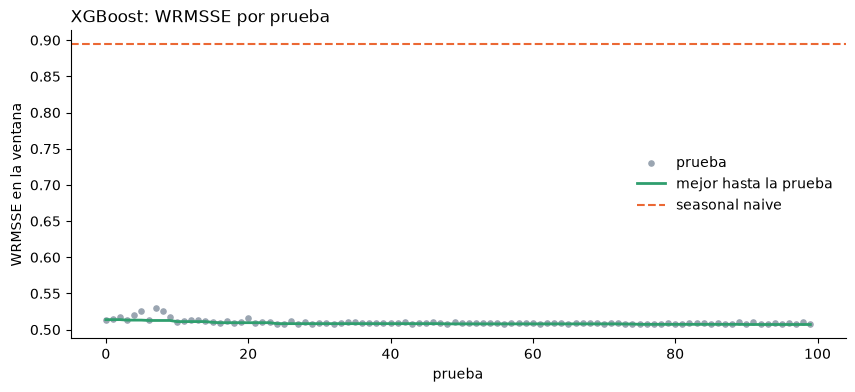

fold,1,2,3,4,5,6,7,8,9,10,11,12,13
WRMSSE,0.382,0.414,0.467,0.361,0.403,0.393,0.352,0.372,0.473,0.419,0.385,0.346,0.353


In [12]:
done = [t for t in xgb_study.trials if t.state == optuna.trial.TrialState.COMPLETE]
assert len(done) >= XGB_TRIALS
trials = pd.DataFrame([{"prueba": t.number, "WRMSSE": t.value, "segundos": t.user_attrs["seconds"], **t.params} for t in done])
print(f"pruebas completas: {len(done)} · {trials['segundos'].sum() / 60:.0f} min en total · "
      f"mejor WRMSSE {xgb_study.best_value:.3f} (prueba {xgb_study.best_trial.number}) · seasonal naive {snaive_wrmsse['todos']:.3f}")
display(trials.sort_values("WRMSSE").head(10).round(4).set_index("prueba"))

# ¿El mejor valor quedó en el borde del espacio? (5 % del rango, en escala log si corresponde)
rows = []
for name, (kind, low, high, *_) in XGB_SPACE.items():
    v = xgb_study.best_params[name]
    f = (np.log(v) - np.log(low)) / (np.log(high) - np.log(low)) if kind == "float_log" else (v - low) / (high - low)
    rows.append({"hiperparámetro": name, "mínimo": low, "máximo": high, "mejor": v, "posición en el rango": round(f, 2),
                 "en el borde": f <= 0.05 or f >= 0.95})
display(pd.DataFrame(rows).set_index("hiperparámetro"))

fig, ax = plt.subplots(figsize=(10, 4))
ax.scatter(trials["prueba"], trials["WRMSSE"], s=14, color="#9aa5b1", label="prueba")
ax.plot(trials["prueba"], trials["WRMSSE"].cummin(), color="#2f9e6e", linewidth=2, label="mejor hasta la prueba")
ax.axhline(snaive_wrmsse["todos"], color="#eb6834", linestyle="--", linewidth=1.5, label="seasonal naive")
ax.set_xlabel("prueba")
ax.set_ylabel("WRMSSE en la ventana")
ax.set_title("XGBoost: WRMSSE por prueba", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()
display(pd.Series(xgb_study.best_trial.user_attrs["wrmsse_fold"], index=range(1, N_FOLDS + 1), name="WRMSSE").rename_axis("fold").round(3).to_frame().T)

### 3.3 · Backtesting de la mejor configuración y guardado

**Qué hace:** repite el backtesting de 13 folds con los hiperparámetros ganadores (Optuna guarda el valor de cada prueba, no sus pronósticos) y lo guarda en `data/interim/nb03c_boosting/xgboost_backtest.pkl` para el nb 03d: un dict con `meta` (hiperparámetros, WRMSSE, variables, semilla, versiones) y `backtest` (una fila por artículo y fold con `units`, `units_prev`, el ratio pronosticado y `pred` en unidades).
**Revisar:** que el WRMSSE repetido coincida con el de la búsqueda (el modelo es determinista con la semilla), el WRMSSE por segmento frente al seasonal naive y cuántos pronósticos salen negativos.

In [13]:
xgb_params = {**XGB_FIXED, **xgb_study.best_params}
xgb_valid = boosting_backtest(boosting_data, BOOST_FEATURES, "xgboost", xgb_params, SEED, N_THREADS, N_FOLDS)

In [14]:
assert len(xgb_valid) == n_items * N_FOLDS and xgb_valid["pred"].notna().all()
xgb_wrmsse = wrmsse_frame(xgb_valid, "pred", rmsse_scale, weights)[0]
assert np.isclose(xgb_wrmsse, xgb_study.best_value, rtol=1e-6), (xgb_wrmsse, xgb_study.best_value)
by_cell = {"todos": xgb_wrmsse}
for cell in ["AX", "AY", "AZ"]:
    by_cell[cell] = wrmsse_frame(xgb_valid[xgb_valid["item_id"].map(cell_of) == cell], "pred", rmsse_scale, weights)[0]
display(pd.DataFrame({"XGBoost": by_cell, "seasonal naive": snaive_wrmsse}).assign(
    **{"XGBoost / seasonal naive": lambda d: d["XGBoost"] / d["seasonal naive"]}).round(3).rename_axis("segmento"))
print(f"pronósticos negativos: {int((xgb_valid['pred'] < 0).sum())} de {len(xgb_valid)}")

,XGBoost,seasonal naive,XGBoost / seasonal naive
segmento,,,
todos,0.507,0.894,0.567
AX,0.556,0.872,0.637
AY,0.476,0.868,0.549
AZ,0.482,1.003,0.481


pronósticos negativos: 0 de 6721


In [15]:
xgb_path = BOOST_DIR / "xgboost_backtest.pkl"
pd.to_pickle({"meta": {"algorithm": "xgboost", "params": xgb_params, "wrmsse": xgb_wrmsse, "trial": xgb_study.best_trial.number,
                       "n_trials": len(done), "features": BOOST_FEATURES, "seed": SEED,
                       "saved_at": pd.Timestamp.now().isoformat(timespec="seconds"),
                       "versions": {lib: version(lib) for lib in ["xgboost-cpu", "optuna", "pandas", "numpy"]}},
              "backtest": xgb_valid}, xgb_path)
back = pd.read_pickle(xgb_path)
pd.testing.assert_frame_equal(back["backtest"], xgb_valid)
print(f"{xgb_path}: {xgb_path.stat().st_size / 1e6:.2f} MB")

data/interim/nb03c_boosting/xgboost_backtest.pkl: 0.44 MB


## Etapa 4 (nb 04, Etapa 13b) · LightGBM: piloto, búsqueda y backtesting

**Objetivo:** elegir los hiperparámetros de un LightGBM global por su WRMSSE en la ventana (13 folds) y guardar el pronóstico de la ventana de la mejor configuración.
**Entradas:** `boosting_data` con `fold`, `BOOST_FEATURES` (Etapa 1), `rmsse_scale`, `weights` y `snaive_wrmsse` (Etapa 2).
**Salidas:** `lgb_pilot` (4.1, en memoria), `lgb_study` (4.2, en `data/interim/nb03c_boosting/lightgbm.db`) y `lgb_valid` (4.3, en `lightgbm_backtest.pkl`).
**Decisión (usuario, 2026-11-06: simple, regularizado, amigable con la RAM):** el mismo criterio que XGBoost, adaptado a cómo crece LightGBM.
- **Fijos:** error cuadrático; `max_depth = 4` como tope de profundidad; `max_bin = 63` (63 cortes por variable en vez de 255: menos RAM, ~400 filas por corte); `subsample_freq = 1` (sin esto `subsample` no actúa); `deterministic` y `force_row_wise` (repetir da los mismos pronósticos, lo que la 4.3 comprueba). Las category (`item_id`, `cell`, `period`) las usa directo, con su regularización por defecto (`cat_smooth` y `cat_l2` = 10, al menos 100 filas por grupo).
- **Espacio:** LightGBM crece hoja por hoja, así que la complejidad se controla con el número de hojas: **3–15 hojas** (menos que las 16 de un árbol de profundidad 4). El resto, igual que XGBoost: 100–600 árboles, tasa 0,01–0,2 (log), 5–100 filas por hoja (log), 60–90 % de filas y 50–90 % de variables por árbol, L2 de 1 a 100 y L1 de 0,01 a 10 (log).
- **100 pruebas**, 6 hilos, piloto de 5 (R7), por las mismas razones que en la Etapa 3. Medido con datos del mismo tamaño: 5 s (3 hojas, 100 árboles) a 20 s (15 hojas, 600 árboles) por prueba → **~20–30 min**; ~260 MB de RAM.

In [16]:
from src.modeling import boosting_backtest, boosting_search

LGB_FIXED = {
    "objective": "regression",                  # error cuadrático: el RMSSE es cuadrático
    "max_depth": 4,                             # tope de profundidad (usuario: árboles poco profundos)
    "max_bin": 63,                              # 63 cortes por variable (por defecto 255): menos RAM, ~400 filas por corte
    "subsample_freq": 1,                        # activa el submuestreo de filas en cada árbol
    "deterministic": True,                      # con force_row_wise: repetir da los mismos pronósticos
    "force_row_wise": True,
    "verbose": -1,                              # sin mensajes por árbol
}
LGB_SPACE = {
    "num_leaves": ("int", 3, 15),               # crece hoja por hoja: a lo sumo 15 hojas (menos que las 16 de profundidad 4)
    "n_estimators": ("int", 100, 600, 50),      # sin early stopping (constitución): la cantidad de árboles se busca
    "learning_rate": ("float_log", 0.01, 0.2),  # pasos chicos regularizan
    "min_child_samples": ("int_log", 5, 100),   # filas mínimas por hoja: sin hojas de pocos bloques
    "subsample": ("float", 0.6, 0.9),           # filas por árbol
    "colsample_bytree": ("float", 0.5, 0.9),    # variables por árbol
    "reg_lambda": ("float_log", 1, 100),        # L2 sobre los valores de las hojas
    "reg_alpha": ("float_log", 0.01, 10),       # L1: lleva hojas poco útiles a 0
}
LGB_PILOT_TRIALS = 5                            # R7: tiempo en distintos puntos del espacio (todas al azar)
LGB_TRIALS = 100                                # 10 al azar + 90 guiadas por el TPE (~11 por hiperparámetro)
LGB_STORAGE = f"sqlite:///{BOOST_DIR / 'lightgbm.db'}"

### 4.1 · Piloto (R7)

**Qué hace:** 5 pruebas en memoria (no se guardan), todas al azar, con 6 hilos.
**Revisar:** segundos por prueba y estimación para las 100, memoria pico del kernel y WRMSSE frente al seasonal naive. Esperar aprobación antes de la 4.2.

In [17]:
t0 = time.perf_counter()
lgb_pilot = boosting_search(boosting_data, BOOST_FEATURES, "lightgbm", LGB_SPACE, LGB_FIXED, rmsse_scale, weights,
                            n_trials=LGB_PILOT_TRIALS, seed=SEED, n_jobs=N_THREADS)
lgb_pilot_wall = time.perf_counter() - t0

  0%|          | 0/5 [00:00<?, ?it/s]

In [18]:
lgb_pilot_tab = pd.DataFrame([{"prueba": t.number, "WRMSSE": t.value, "segundos": t.user_attrs["seconds"],
                               "negativos": t.user_attrs["n_negative"], **t.params} for t in lgb_pilot.trials])
assert len(lgb_pilot_tab) == LGB_PILOT_TRIALS and lgb_pilot_tab["WRMSSE"].notna().all()
assert (pd.DataFrame([t.user_attrs for t in lgb_pilot.trials])["n_excluded"] == 0).all()
display(lgb_pilot_tab.round(3))
lgb_per_trial = lgb_pilot_tab["segundos"].mean()
print(f"piloto: {lgb_pilot_wall / 60:.1f} min · {lgb_per_trial:.0f} s por prueba (máx. {lgb_pilot_tab['segundos'].max():.0f} s) · "
      f"estimación para {LGB_TRIALS} pruebas: {lgb_per_trial * LGB_TRIALS / 60:.0f} min")
print(f"memoria pico del kernel: {resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e3:,.0f} MB")
print(f"WRMSSE: mejor del piloto {lgb_pilot_tab['WRMSSE'].min():.3f} · seasonal naive {snaive_wrmsse['todos']:.3f}")

,prueba,WRMSSE,segundos,negativos,num_leaves,n_estimators,learning_rate,min_child_samples,subsample,colsample_bytree,reg_lambda,reg_alpha
0,0,0.518,21.775,0,7,600,0.090,29,0.647,0.562,1.307,3.968
1,1,0.515,17.425,0,10,450,0.011,92,0.850,0.585,2.310,0.035
2,2,0.517,11.691,0,6,350,0.036,11,0.784,0.556,3.840,0.126
3,3,0.515,16.135,0,8,500,0.018,22,0.778,0.519,16.409,0.032
4,4,0.523,14.406,0,3,600,0.180,55,0.691,0.539,23.360,0.209


piloto: 1.4 min · 16 s por prueba (máx. 22 s) · estimación para 100 pruebas: 27 min
memoria pico del kernel: 391 MB
WRMSSE: mejor del piloto 0.515 · seasonal naive 0.894


### 4.2 · Búsqueda de hiperparámetros

**Qué hace:** 100 pruebas del TPE, cada una un backtesting de 13 folds, guardadas al terminar en `data/interim/nb03c_boosting/lightgbm.db`. Se retoma al relanzar la celda; si cambió el espacio, los fijos o las variables, se detiene (para empezar de cero, borrar el archivo).
**Revisar:** cómo baja el mejor WRMSSE con las pruebas, si algún hiperparámetro quedó en el borde del espacio y el WRMSSE por fold de la mejor configuración.

In [19]:
print(f"artículos: {n_items} · filas: {len(boosting_data):,} · exportado por el 03b: {manifest['saved_at']} · estudio: {LGB_STORAGE}")
lgb_study = boosting_search(boosting_data, BOOST_FEATURES, "lightgbm", LGB_SPACE, LGB_FIXED, rmsse_scale, weights,
                            n_trials=LGB_TRIALS, seed=SEED, n_jobs=N_THREADS, storage=LGB_STORAGE, study_name="lightgbm")

artículos: 517 · filas: 31,164 · exportado por el 03b: 2026-11-07T08:25:38 · estudio: sqlite:///data/interim/nb03c_boosting/lightgbm.db


  0%|          | 0/100 [00:00<?, ?it/s]

pruebas completas: 100 · 35 min en total · mejor WRMSSE 0.511 (prueba 31) · seasonal naive 0.894


,WRMSSE,segundos,num_leaves,n_estimators,learning_rate,min_child_samples,subsample,colsample_bytree,reg_lambda,reg_alpha
prueba,,,,,,,,,,
31,0.5109,25.4937,15,450,0.0570,91,0.8495,0.8534,3.9603,1.9909
59,0.5110,16.6912,14,400,0.0978,91,0.8913,0.8500,5.4238,2.4731
71,0.5111,25.1239,15,550,0.0414,50,0.8063,0.8433,2.9741,4.7083
65,0.5112,29.0142,15,550,0.0479,71,0.8187,0.8865,2.9667,5.8516
55,0.5113,15.5172,14,400,0.0763,76,0.8660,0.8853,7.2484,3.7186
95,0.5113,22.1697,15,550,0.0446,60,0.8057,0.8636,3.5333,6.3303
91,0.5114,22.7947,15,500,0.0552,82,0.8374,0.8773,1.9224,5.2920
49,0.5114,21.3623,15,550,0.0514,51,0.8081,0.8472,3.1897,8.3129
93,0.5116,28.1271,15,550,0.0419,52,0.8101,0.8910,2.9961,4.4672


,mínimo,máximo,mejor,posición en el rango,en el borde
hiperparámetro,,,,,
num_leaves,3.00,15.0,15.000000,1.00,True
n_estimators,100.00,600.0,450.000000,0.70,False
learning_rate,0.01,0.2,0.057023,0.58,False
min_child_samples,5.00,100.0,91.000000,0.97,True
subsample,0.60,0.9,0.849547,0.83,False
colsample_bytree,0.50,0.9,0.853364,0.88,False
reg_lambda,1.00,100.0,3.960251,0.30,False
reg_alpha,0.01,10.0,1.990897,0.77,False


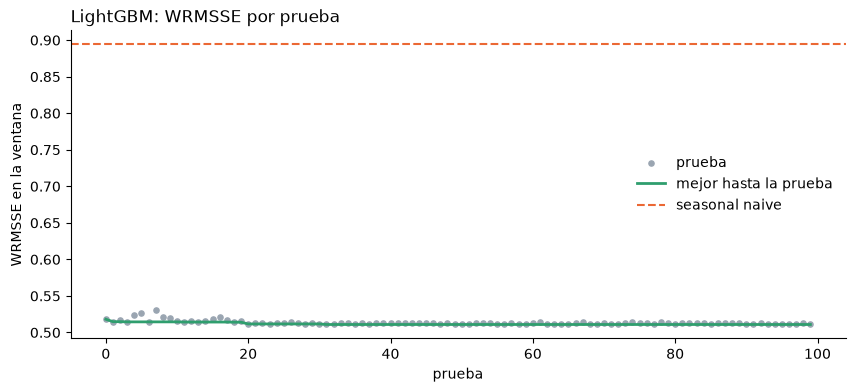

fold,1,2,3,4,5,6,7,8,9,10,11,12,13
WRMSSE,0.388,0.412,0.463,0.368,0.405,0.383,0.35,0.376,0.484,0.412,0.392,0.351,0.356


In [20]:
lgb_done = [t for t in lgb_study.trials if t.state == optuna.trial.TrialState.COMPLETE]
assert len(lgb_done) >= LGB_TRIALS
lgb_trials = pd.DataFrame([{"prueba": t.number, "WRMSSE": t.value, "segundos": t.user_attrs["seconds"], **t.params} for t in lgb_done])
print(f"pruebas completas: {len(lgb_done)} · {lgb_trials['segundos'].sum() / 60:.0f} min en total · "
      f"mejor WRMSSE {lgb_study.best_value:.3f} (prueba {lgb_study.best_trial.number}) · seasonal naive {snaive_wrmsse['todos']:.3f}")
display(lgb_trials.sort_values("WRMSSE").head(10).round(4).set_index("prueba"))

# ¿El mejor valor quedó en el borde del espacio? (5 % del rango, en escala log si corresponde)
rows = []
for name, (kind, low, high, *_) in LGB_SPACE.items():
    v = lgb_study.best_params[name]
    log = kind in ("float_log", "int_log")
    f = (np.log(v) - np.log(low)) / (np.log(high) - np.log(low)) if log else (v - low) / (high - low)
    rows.append({"hiperparámetro": name, "mínimo": low, "máximo": high, "mejor": v, "posición en el rango": round(f, 2),
                 "en el borde": f <= 0.05 or f >= 0.95})
display(pd.DataFrame(rows).set_index("hiperparámetro"))

fig, ax = plt.subplots(figsize=(10, 4))
ax.scatter(lgb_trials["prueba"], lgb_trials["WRMSSE"], s=14, color="#9aa5b1", label="prueba")
ax.plot(lgb_trials["prueba"], lgb_trials["WRMSSE"].cummin(), color="#2f9e6e", linewidth=2, label="mejor hasta la prueba")
ax.axhline(snaive_wrmsse["todos"], color="#eb6834", linestyle="--", linewidth=1.5, label="seasonal naive")
ax.set_xlabel("prueba")
ax.set_ylabel("WRMSSE en la ventana")
ax.set_title("LightGBM: WRMSSE por prueba", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()
display(pd.Series(lgb_study.best_trial.user_attrs["wrmsse_fold"], index=range(1, N_FOLDS + 1), name="WRMSSE").rename_axis("fold").round(3).to_frame().T)

### 4.3 · Backtesting de la mejor configuración y guardado

**Qué hace:** repite el backtesting de 13 folds con los hiperparámetros ganadores y lo guarda en `data/interim/nb03c_boosting/lightgbm_backtest.pkl` para el nb 03d, con la misma estructura que el de XGBoost (`meta` y `backtest`).
**Revisar:** que el WRMSSE repetido coincida con el de la búsqueda, el WRMSSE por segmento frente al seasonal naive y a XGBoost, y cuántos pronósticos salen negativos.

In [21]:
lgb_params = {**LGB_FIXED, **lgb_study.best_params}
lgb_valid = boosting_backtest(boosting_data, BOOST_FEATURES, "lightgbm", lgb_params, SEED, N_THREADS, N_FOLDS)

In [22]:
assert len(lgb_valid) == n_items * N_FOLDS and lgb_valid["pred"].notna().all()
lgb_wrmsse = wrmsse_frame(lgb_valid, "pred", rmsse_scale, weights)[0]
assert np.isclose(lgb_wrmsse, lgb_study.best_value, rtol=1e-6), (lgb_wrmsse, lgb_study.best_value)
lgb_by_cell = {"todos": lgb_wrmsse}
for cell in ["AX", "AY", "AZ"]:
    lgb_by_cell[cell] = wrmsse_frame(lgb_valid[lgb_valid["item_id"].map(cell_of) == cell], "pred", rmsse_scale, weights)[0]
display(pd.DataFrame({"LightGBM": lgb_by_cell, "XGBoost": by_cell, "seasonal naive": snaive_wrmsse}).assign(
    **{"LightGBM / seasonal naive": lambda d: d["LightGBM"] / d["seasonal naive"]}).round(3).rename_axis("segmento"))
print(f"pronósticos negativos: {int((lgb_valid['pred'] < 0).sum())} de {len(lgb_valid)}")

,LightGBM,XGBoost,seasonal naive,LightGBM / seasonal naive
segmento,,,,
todos,0.511,0.507,0.894,0.571
AX,0.564,0.556,0.872,0.647
AY,0.478,0.476,0.868,0.551
AZ,0.481,0.482,1.003,0.480


pronósticos negativos: 0 de 6721


In [23]:
lgb_path = BOOST_DIR / "lightgbm_backtest.pkl"
pd.to_pickle({"meta": {"algorithm": "lightgbm", "params": lgb_params, "wrmsse": lgb_wrmsse, "trial": lgb_study.best_trial.number,
                       "n_trials": len(lgb_done), "features": BOOST_FEATURES, "seed": SEED,
                       "saved_at": pd.Timestamp.now().isoformat(timespec="seconds"),
                       "versions": {lib: version(lib) for lib in ["lightgbm", "optuna", "pandas", "numpy"]}},
              "backtest": lgb_valid}, lgb_path)
back = pd.read_pickle(lgb_path)
pd.testing.assert_frame_equal(back["backtest"], lgb_valid)
print(f"{lgb_path}: {lgb_path.stat().st_size / 1e6:.2f} MB")

data/interim/nb03c_boosting/lightgbm_backtest.pkl: 0.46 MB


## Etapa 5 (nb 04, Etapa 13c) · CatBoost: piloto, búsqueda y backtesting

**Objetivo:** elegir los hiperparámetros de un CatBoost global por su WRMSSE en la ventana (13 folds) y guardar el pronóstico de la ventana de la mejor configuración.
**Entradas:** `boosting_data` con `fold`, `BOOST_FEATURES` y `CAT_FEATURES` (Etapa 1), `rmsse_scale`, `weights` y `snaive_wrmsse` (Etapa 2).
**Salidas:** `cat_pilot` (5.1, en memoria), `cat_study` (5.2, en `data/interim/nb03c_boosting/catboost.db`) y `cat_valid` (5.3, en `catboost_backtest.pkl`).
**Decisión (usuario, 2026-11-06: simple, regularizado, amigable con la RAM):** el mismo criterio, adaptado a CatBoost.
- **Árboles simétricos:** CatBoost usa la misma condición en todo un nivel, así que la profundidad 2–4 da exactamente 4–16 hojas. No tiene mínimo de filas por hoja con estos árboles: la regularización va por L2 y por el ruido en la elección de cortes.
- **Fijos:** error cuadrático (`RMSE`); `border_count = 64` (64 cortes por variable en vez de 254: menos RAM); submuestreo de filas `Bernoulli`; `cat_features` = `item_id`, `cell` y `period`, que CatBoost codifica con estadísticas ordenadas del objetivo (su principal defensa contra el sobreajuste en categóricas).
- **`boosting_type = "Plain"`** y no `"Ordered"` (el valor por defecto con pocos datos). Medido con datos del mismo tamaño: Plain 6–42 s por prueba y ~500 MB; Ordered 5–62 s y ~600 MB. La codificación ordenada de las categóricas se mantiene en los dos modos.
- **Espacio:** profundidad 2–4, 100–600 árboles, tasa 0,01–0,2 (log), L2 de 1 a 100 (log), `random_strength` 0,1–10 (log: ruido en los cortes, regulariza), 60–90 % de filas y 50–90 % de variables por nivel (`rsm`). CatBoost no tiene L1.
- **100 pruebas**, 6 hilos, piloto de 5 (R7), como en las Etapas 3 y 4. Es el más lento de los tres: **~35–45 min**. Repetir da los mismos pronósticos (verificado).

In [24]:
from src.modeling import boosting_backtest, boosting_search

CAT_FIXED = {
    "loss_function": "RMSE",                    # error cuadrático: el RMSSE es cuadrático
    "border_count": 64,                         # 64 cortes por variable (por defecto 254): menos RAM
    "bootstrap_type": "Bernoulli",              # submuestreo de filas con `subsample`
    "boosting_type": "Plain",                   # más rápido y con menos RAM que Ordered (medido); categóricas ordenadas igual
    "cat_features": CAT_FEATURES,               # item_id, cell y period con estadísticas ordenadas del objetivo
}
CAT_SPACE = {
    "depth": ("int", 2, 4),                     # árboles simétricos: exactamente 4–16 hojas
    "n_estimators": ("int", 100, 600, 50),      # sin early stopping (constitución): la cantidad de árboles se busca
    "learning_rate": ("float_log", 0.01, 0.2),  # pasos chicos regularizan
    "l2_leaf_reg": ("float_log", 1, 100),       # L2 sobre los valores de las hojas
    "random_strength": ("float_log", 0.1, 10),  # ruido en el puntaje de los cortes: evita cortes que solo calzan con el train
    "subsample": ("float", 0.6, 0.9),           # filas por árbol
    "rsm": ("float", 0.5, 0.9),                 # variables por nivel
}
CAT_PILOT_TRIALS = 5                            # R7: tiempo en distintos puntos del espacio (todas al azar)
CAT_TRIALS = 100                                # 10 al azar + 90 guiadas por el TPE (~13 por hiperparámetro)
CAT_STORAGE = f"sqlite:///{BOOST_DIR / 'catboost.db'}"

### 5.1 · Piloto (R7)

**Qué hace:** 5 pruebas en memoria (no se guardan), todas al azar, con 6 hilos.
**Revisar:** segundos por prueba y estimación para las 100, memoria pico del kernel y WRMSSE frente al seasonal naive. Esperar aprobación antes de la 5.2.

In [25]:
t0 = time.perf_counter()
cat_pilot = boosting_search(boosting_data, BOOST_FEATURES, "catboost", CAT_SPACE, CAT_FIXED, rmsse_scale, weights,
                            n_trials=CAT_PILOT_TRIALS, seed=SEED, n_jobs=N_THREADS)
cat_pilot_wall = time.perf_counter() - t0

  0%|          | 0/5 [00:00<?, ?it/s]

In [26]:
cat_pilot_tab = pd.DataFrame([{"prueba": t.number, "WRMSSE": t.value, "segundos": t.user_attrs["seconds"],
                               "negativos": t.user_attrs["n_negative"], **t.params} for t in cat_pilot.trials])
assert len(cat_pilot_tab) == CAT_PILOT_TRIALS and cat_pilot_tab["WRMSSE"].notna().all()
assert (pd.DataFrame([t.user_attrs for t in cat_pilot.trials])["n_excluded"] == 0).all()
display(cat_pilot_tab.round(3))
cat_per_trial = cat_pilot_tab["segundos"].mean()
print(f"piloto: {cat_pilot_wall / 60:.1f} min · {cat_per_trial:.0f} s por prueba (máx. {cat_pilot_tab['segundos'].max():.0f} s) · "
      f"estimación para {CAT_TRIALS} pruebas: {cat_per_trial * CAT_TRIALS / 60:.0f} min")
print(f"memoria pico del kernel: {resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e3:,.0f} MB")
print(f"WRMSSE: mejor del piloto {cat_pilot_tab['WRMSSE'].min():.3f} · seasonal naive {snaive_wrmsse['todos']:.3f}")

,prueba,WRMSSE,segundos,negativos,depth,n_estimators,learning_rate,l2_leaf_reg,random_strength,subsample,rsm
0,0,0.513,54.402,0,3,600,0.090,15.751,0.205,0.647,0.523
1,1,0.511,48.802,0,4,400,0.083,1.099,8.706,0.850,0.585
2,2,0.522,14.144,0,2,200,0.025,11.208,0.731,0.687,0.745
3,3,0.525,16.568,0,2,250,0.030,8.168,3.718,0.660,0.706
4,4,0.519,8.418,0,3,100,0.062,2.193,0.135,0.885,0.886


piloto: 2.4 min · 28 s por prueba (máx. 54 s) · estimación para 100 pruebas: 47 min
memoria pico del kernel: 557 MB
WRMSSE: mejor del piloto 0.511 · seasonal naive 0.894


### 5.2 · Búsqueda de hiperparámetros

**Qué hace:** 100 pruebas del TPE, cada una un backtesting de 13 folds, guardadas al terminar en `data/interim/nb03c_boosting/catboost.db`. Se retoma al relanzar la celda; si cambió el espacio, los fijos o las variables, se detiene (para empezar de cero, borrar el archivo).
**Revisar:** cómo baja el mejor WRMSSE con las pruebas, si algún hiperparámetro quedó en el borde del espacio y el WRMSSE por fold de la mejor configuración.

In [27]:
print(f"artículos: {n_items} · filas: {len(boosting_data):,} · exportado por el 03b: {manifest['saved_at']} · estudio: {CAT_STORAGE}")
cat_study = boosting_search(boosting_data, BOOST_FEATURES, "catboost", CAT_SPACE, CAT_FIXED, rmsse_scale, weights,
                            n_trials=CAT_TRIALS, seed=SEED, n_jobs=N_THREADS, storage=CAT_STORAGE, study_name="catboost")

artículos: 517 · filas: 31,164 · exportado por el 03b: 2026-11-07T08:25:38 · estudio: sqlite:///data/interim/nb03c_boosting/catboost.db


  0%|          | 0/100 [00:00<?, ?it/s]

pruebas completas: 100 · 66 min en total · mejor WRMSSE 0.506 (prueba 43) · seasonal naive 0.894


,WRMSSE,segundos,depth,n_estimators,learning_rate,l2_leaf_reg,random_strength,subsample,rsm
prueba,,,,,,,,,
43,0.5062,44.2196,4,450,0.0711,2.9097,0.1148,0.7368,0.5024
70,0.5068,59.1072,4,600,0.0390,4.3087,0.2094,0.6835,0.5132
53,0.5070,44.2996,4,450,0.0605,2.9327,0.1969,0.7640,0.5445
75,0.5071,35.2958,4,550,0.0465,5.3650,0.1069,0.6751,0.5390
83,0.5073,27.9408,4,550,0.0444,5.6937,0.1652,0.6633,0.5249
63,0.5073,53.2272,4,550,0.0437,8.0962,0.1220,0.6790,0.5386
40,0.5074,49.9781,4,500,0.0364,3.9021,0.1261,0.6946,0.5664
61,0.5074,54.0252,4,550,0.0455,3.1517,0.1252,0.6889,0.5087
85,0.5075,31.7066,4,600,0.0567,4.1898,0.2128,0.6857,0.5346


,mínimo,máximo,mejor,posición en el rango,en el borde
hiperparámetro,,,,,
depth,2.00,4.0,4.000000,1.00,True
n_estimators,100.00,600.0,450.000000,0.70,False
learning_rate,0.01,0.2,0.071058,0.65,False
l2_leaf_reg,1.00,100.0,2.909726,0.23,False
random_strength,0.10,10.0,0.114783,0.03,True
subsample,0.60,0.9,0.736753,0.46,False
rsm,0.50,0.9,0.502400,0.01,True


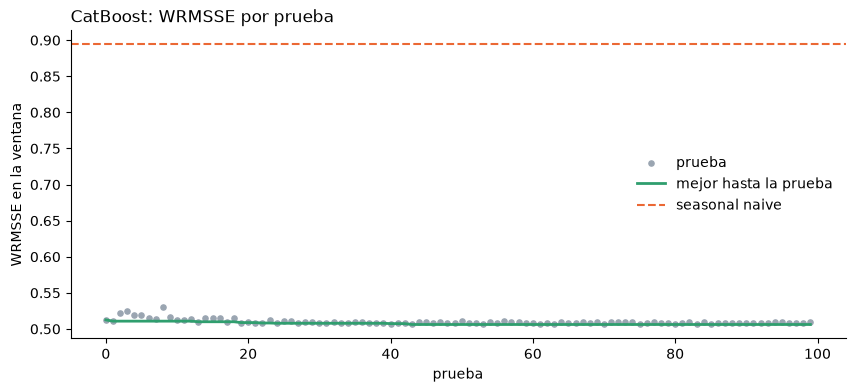

fold,1,2,3,4,5,6,7,8,9,10,11,12,13
WRMSSE,0.375,0.414,0.462,0.365,0.409,0.392,0.351,0.384,0.476,0.403,0.382,0.345,0.35


In [28]:
cat_done = [t for t in cat_study.trials if t.state == optuna.trial.TrialState.COMPLETE]
assert len(cat_done) >= CAT_TRIALS
cat_trials = pd.DataFrame([{"prueba": t.number, "WRMSSE": t.value, "segundos": t.user_attrs["seconds"], **t.params} for t in cat_done])
print(f"pruebas completas: {len(cat_done)} · {cat_trials['segundos'].sum() / 60:.0f} min en total · "
      f"mejor WRMSSE {cat_study.best_value:.3f} (prueba {cat_study.best_trial.number}) · seasonal naive {snaive_wrmsse['todos']:.3f}")
display(cat_trials.sort_values("WRMSSE").head(10).round(4).set_index("prueba"))

# ¿El mejor valor quedó en el borde del espacio? (5 % del rango, en escala log si corresponde)
rows = []
for name, (kind, low, high, *_) in CAT_SPACE.items():
    v = cat_study.best_params[name]
    log = kind in ("float_log", "int_log")
    f = (np.log(v) - np.log(low)) / (np.log(high) - np.log(low)) if log else (v - low) / (high - low)
    rows.append({"hiperparámetro": name, "mínimo": low, "máximo": high, "mejor": v, "posición en el rango": round(f, 2),
                 "en el borde": f <= 0.05 or f >= 0.95})
display(pd.DataFrame(rows).set_index("hiperparámetro"))

fig, ax = plt.subplots(figsize=(10, 4))
ax.scatter(cat_trials["prueba"], cat_trials["WRMSSE"], s=14, color="#9aa5b1", label="prueba")
ax.plot(cat_trials["prueba"], cat_trials["WRMSSE"].cummin(), color="#2f9e6e", linewidth=2, label="mejor hasta la prueba")
ax.axhline(snaive_wrmsse["todos"], color="#eb6834", linestyle="--", linewidth=1.5, label="seasonal naive")
ax.set_xlabel("prueba")
ax.set_ylabel("WRMSSE en la ventana")
ax.set_title("CatBoost: WRMSSE por prueba", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()
display(pd.Series(cat_study.best_trial.user_attrs["wrmsse_fold"], index=range(1, N_FOLDS + 1), name="WRMSSE").rename_axis("fold").round(3).to_frame().T)

### 5.3 · Backtesting de la mejor configuración y guardado

**Qué hace:** repite el backtesting de 13 folds con los hiperparámetros ganadores y lo guarda en `data/interim/nb03c_boosting/catboost_backtest.pkl` para el nb 03d, con la misma estructura que los otros dos (`meta` y `backtest`).
**Revisar:** que el WRMSSE repetido coincida con el de la búsqueda, el WRMSSE por segmento de los tres boosting frente al seasonal naive y cuántos pronósticos salen negativos.

In [29]:
cat_params = {**CAT_FIXED, **cat_study.best_params}
cat_valid = boosting_backtest(boosting_data, BOOST_FEATURES, "catboost", cat_params, SEED, N_THREADS, N_FOLDS)

In [30]:
assert len(cat_valid) == n_items * N_FOLDS and cat_valid["pred"].notna().all()
cat_wrmsse = wrmsse_frame(cat_valid, "pred", rmsse_scale, weights)[0]
assert np.isclose(cat_wrmsse, cat_study.best_value, rtol=1e-6), (cat_wrmsse, cat_study.best_value)
cat_by_cell = {"todos": cat_wrmsse}
for cell in ["AX", "AY", "AZ"]:
    cat_by_cell[cell] = wrmsse_frame(cat_valid[cat_valid["item_id"].map(cell_of) == cell], "pred", rmsse_scale, weights)[0]
display(pd.DataFrame({"CatBoost": cat_by_cell, "LightGBM": lgb_by_cell, "XGBoost": by_cell, "seasonal naive": snaive_wrmsse})
        .round(3).rename_axis("segmento").style.set_caption("WRMSSE en la ventana (13 folds) por segmento"))
print(f"pronósticos negativos: {int((cat_valid['pred'] < 0).sum())} de {len(cat_valid)}")

,CatBoost,LightGBM,XGBoost,seasonal naive
segmento,,,,
todos,0.506000,0.511000,0.507000,0.894000
AX,0.555000,0.564000,0.556000,0.872000
AY,0.475000,0.478000,0.476000,0.868000
AZ,0.483000,0.481000,0.482000,1.003000


pronósticos negativos: 0 de 6721


In [31]:
cat_path = BOOST_DIR / "catboost_backtest.pkl"
pd.to_pickle({"meta": {"algorithm": "catboost", "params": cat_params, "wrmsse": cat_wrmsse, "trial": cat_study.best_trial.number,
                       "n_trials": len(cat_done), "features": BOOST_FEATURES, "seed": SEED,
                       "saved_at": pd.Timestamp.now().isoformat(timespec="seconds"),
                       "versions": {lib: version(lib) for lib in ["catboost", "optuna", "pandas", "numpy"]}},
              "backtest": cat_valid}, cat_path)
back = pd.read_pickle(cat_path)
pd.testing.assert_frame_equal(back["backtest"], cat_valid)
print(f"{cat_path}: {cat_path.stat().st_size / 1e6:.2f} MB")

data/interim/nb03c_boosting/catboost_backtest.pkl: 0.46 MB


## Cierre

**Qué queda:** en `data/interim/nb03c_boosting/`, por algoritmo, el estudio de Optuna (`<algoritmo>.db`, todas las pruebas con su WRMSSE por fold) y el pronóstico de la ventana de la mejor configuración (`<algoritmo>_backtest.pkl`).
**Siguiente paso:** el nb 03d junta estos pronósticos con los de SARIMAX (`data/interim/nb03b_sarimax/`) y el seasonal naive (`data/interim/nb03b_datasets/`), aplica el filtro frente al seasonal naive y elige el modelo por artículo. Allí se anota el límite de la Etapa 0: los hiperparámetros del boosting se eligieron con los mismos 13 folds con los que compite.